In [1]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

Mounted at /content/drive/


In [2]:
!pip install -e /content/drive/MyDrive/ve/variance_analysis

Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Attempting uninstall: variance_analysis
    Found existing installation: variance_analysis 0.1.0
    Uninstalling variance_analysis-0.1.0:
      Successfully uninstalled variance_analysis-0.1.0
  Running setup.py develop for variance_analysis


# 1D Decoding Analysis

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct
import os
from pathlib import Path

current_file_path = Path().resolve()#.parent
current_file_path

PosixPath('/content/drive/MyDrive/ve/variance_analysis')

## Decode HD from Pfeiffer place cells

In [21]:
current_file_path = Path().resolve().parent

# heads up the pfeiffer data uses much slower rates!! 5 is good for dusz
velocity_filter = 1 #0.03 # cm/s

save_path = current_file_path / f'results/rodents/pfeiffer'
data_path = current_file_path / f'data/rodents/pfeiffer'

rats = [1,2,3,4]
rat_neurons = [204, 174, 79, 94]



In [22]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

for i, dataset_dict in datasets.items():
    for rat in rats:
        ! python src/pfeiffer_decode_solo.py --rat {rat} --mode xy --cv_folds 4 --vel_threshold {velocity_filter} --smooth_sigma=1 --save_intermediates
        ! python src/pfeiffer_decode_solo.py --rat {rat} --mode hd --cv_folds 4 --vel_threshold {velocity_filter} --smooth_sigma=1 --save_intermediates

os.chdir('notebooks')

NameError: name 'datasets' is not defined

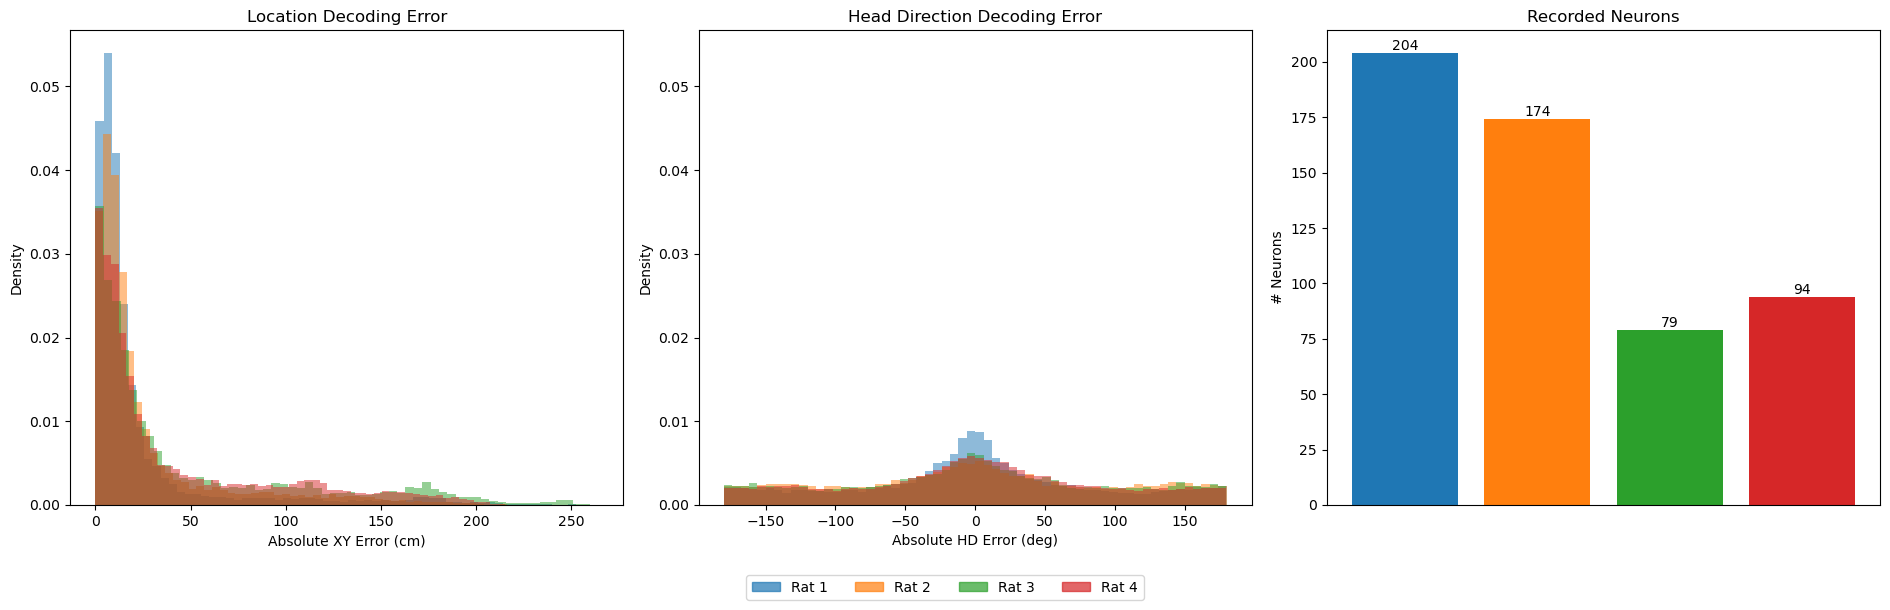

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(19, 6))

colors = plt.cm.tab10.colors  # consistent colormap
handles = []  # for legend
labels = []

for i, rat in enumerate(rats):
    save_path_rat = save_path / f"Rat{rat}"
    error_files_xy = sorted(save_path_rat.glob("errors_xy_cv*_17x17.npz"))
    error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_60.npz"))

    all_errors_xy, all_errors_hd = [], []

    for f in error_files_xy:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_xy.append(np.asarray(data["errors_cm"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (XY): {e}")

    for f in error_files_hd:
        try:
            data = np.load(f, allow_pickle=True)
            all_errors_hd.append(np.asarray(data["errors_deg"]).ravel())
        except Exception as e:
            print(f"[Rat {rat}] Skipping {f} (HD): {e}")

    if all_errors_xy:
        all_errors_xy = np.concatenate(all_errors_xy)
        h = axs[0].hist(
            all_errors_xy[~np.isnan(all_errors_xy)],
            bins=60,
            alpha=0.5,
            density=True,
            color=colors[i],
        )

    if all_errors_hd:
        all_errors_hd = np.concatenate(all_errors_hd)
        axs[1].hist(
            all_errors_hd[~np.isnan(all_errors_hd)],
            bins=60,
            alpha=0.5,
            density=True,
            color=colors[i],
        )

    # Bars for neuron counts
    axs[2].bar(i, rat_neurons[i], color=colors[i])

    # collect handles/labels once for shared legend
    handles.append(plt.Rectangle((0, 0), 1, 1, color=colors[i], alpha=0.7))
    labels.append(f"Rat {rat}")

axs[1].set_ylim(axs[0].get_ylim())

# XY
axs[0].set_xlabel("Absolute XY Error (cm)")
axs[0].set_ylabel("Density")
axs[0].set_title("Location Decoding Error")

# HD
axs[1].set_xlabel("Absolute HD Error (deg)")
axs[1].set_ylabel("Density")
axs[1].set_title("Head Direction Decoding Error")

# Bar plot
axs[2].set_xticks([])  # no labels
axs[2].set_ylabel("# Neurons")
axs[2].set_title("Recorded Neurons")

for rect in axs[2].patches:
    height = rect.get_height()
    axs[2].text(
        rect.get_x() + rect.get_width() / 2.0,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
    )

# Shared legend below figure
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(rats),
    bbox_to_anchor=(0.5, -0.02),
)


plt.tight_layout()
plt.subplots_adjust(bottom=0.15)  # leave space for legend
plt.savefig(current_file_path.parent / 'figs/pfeiffer_1d_decoding.png', dpi=300)
plt.show()


## Decoding from Dusz HD cells

In [4]:
# heads up the pfeiffer data uses much slower rates!! 5 is good for dusz
velocity_filter = 2 #0.03 # cm/s

save_path = current_file_path / f'results/rodents/dusz'
data_path = current_file_path / f'data/rodents/dusz'

dataset_n = list(range(1,3))
smoothing = 20


In [5]:
# filter by env type

dusz_datasets = {}

from openpyxl import load_workbook

wb = load_workbook(data_path / f"Dataset_metadata.xlsx")

for n in dataset_n:
    sheet = wb[f'Dataset_{n}']

    dataset_dict = {}
    try:
      actual = os.listdir(data_path / f'Dataset_{n}')
    except Exception as e:
      continue
    for row in sheet.iter_rows(values_only=True):
        if not row[0] or row[0][0] != 'A':
            continue
        key = row[0]
        if key not in actual:
            print("Actual dataset missing", key)
        values = (row[3], row[9]) # environment shapes and neurons
        dataset_dict[key] = values
    dusz_datasets[n] = dataset_dict


In [9]:
# create ratemaps, then jointly decode hd & md
#from src.dusz_decode_solo import decode_solo
#os.chdir('..')

reload = True

n_hd_bins = 360

for n, rats in dusz_datasets.items():
    for rat, (env_type, _) in rats.items():
        if env_type == 'Square' or rat == 'A3708-200317b':
            # also this is dumb and should be calling a function from a script not doing this
            # for now this just decodes from epoch 1 but some of epoch 2 is also square lol
            # I fixed this in another branch, need to port it over.

            #if rat != 'A1815-190523':
              # just testing
            #  continue

            try:
              print(os.listdir(save_path / f'Dataset_{n}/{rat}'))
              if not reload and f'errors_hd_cv0_{n_hd_bins}_all.npz' in os.listdir(save_path / f'Dataset_{n}/{rat}'):
                continue
            except Exception as e:
              pass
            '''
            decode_solo(
                data_path=data_path,
                save_path=save_path,
                dataset=n,
                rat=rat,
                mode='xy',
                vel_threshold=velocity_filter,
                cv_folds=4,
                smooth_sigma=1,
                save_intermediates=True
              )
            decode_solo(
                data_path=data_path,
                save_path=save_path,
                dataset=n,
                rat=rat,
                mode='hd',
                vel_threshold=velocity_filter,
                cv_folds=4,
                smooth_sigma=1,
                save_intermediates=True
              )
            decode_solo(
                data_path=data_path,
                save_path=save_path,
                dataset=n,
                rat=rat,
                mode='md',
                vel_threshold=velocity_filter,
                cv_folds=4,
                smooth_sigma=1,
                save_intermediates=True
              )

              '''

            ! python src/dusz_decode_solo.py --dataset {n} --rat {rat} --data_path {data_path} --save_path {save_path} --n_hd_bins {n_hd_bins} --n_md_bins {n_hd_bins} --vel_threshold {velocity_filter} --cv_folds 4 --smooth_sigma=3 --save_intermediates

#os.chdir('notebooks')


['xy_rate_map_cv0_10x10_train.npy', 'cv_mask_xy0_10x10.npy', 'decoded_xy_cv0_10x10.npy', 'decoded_xy_cv0_10x10_time_centers.npy', 'xy_occupancy_map_cv0_10x10.npy', 'decoded_xy_cv0_10x10_posterior.npy', 'xy_rate_map_cv1_10x10_train.npy', 'errors_xy_cv0_10x10.npz', 'decoded_xy_cv1_10x10.npy', 'decoded_xy_cv1_10x10_time_centers.npy', 'xy_occupancy_map_cv1_10x10.npy', 'decoded_xy_cv1_10x10_posterior.npy', 'cv_mask_xy1_10x10.npy', 'xy_rate_map_cv2_10x10_train.npy', 'errors_xy_cv1_10x10.npz', 'cv_mask_xy2_10x10.npy', 'xy_occupancy_map_cv2_10x10.npy', 'decoded_xy_cv2_10x10.npy', 'decoded_xy_cv2_10x10_time_centers.npy', 'decoded_xy_cv2_10x10_posterior.npy', 'errors_xy_cv2_10x10.npz', 'decoded_xy_cv3_10x10.npy', 'xy_rate_map_cv3_10x10_train.npy', 'decoded_xy_cv3_10x10_time_centers.npy', 'xy_occupancy_map_cv3_10x10.npy', 'cv_mask_xy3_10x10.npy', 'decoded_xy_cv3_10x10_posterior.npy', 'errors_xy_cv3_10x10.npz', 'cv_summary_xy_10x10.json', 'hd_rate_map_cv0_17_train.npy', 'decoded_hd_cv0_17_time_cen

In [8]:
!pwd

/content/drive/MyDrive/ve/variance_analysis


In [9]:
!ls /content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/

Dataset_1  hd_neuron_counts.json  rate_maps_summary.pdf


### Decoding XY from Dusz HD cells

/tmp/ipython-input-2211546798.py:164: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


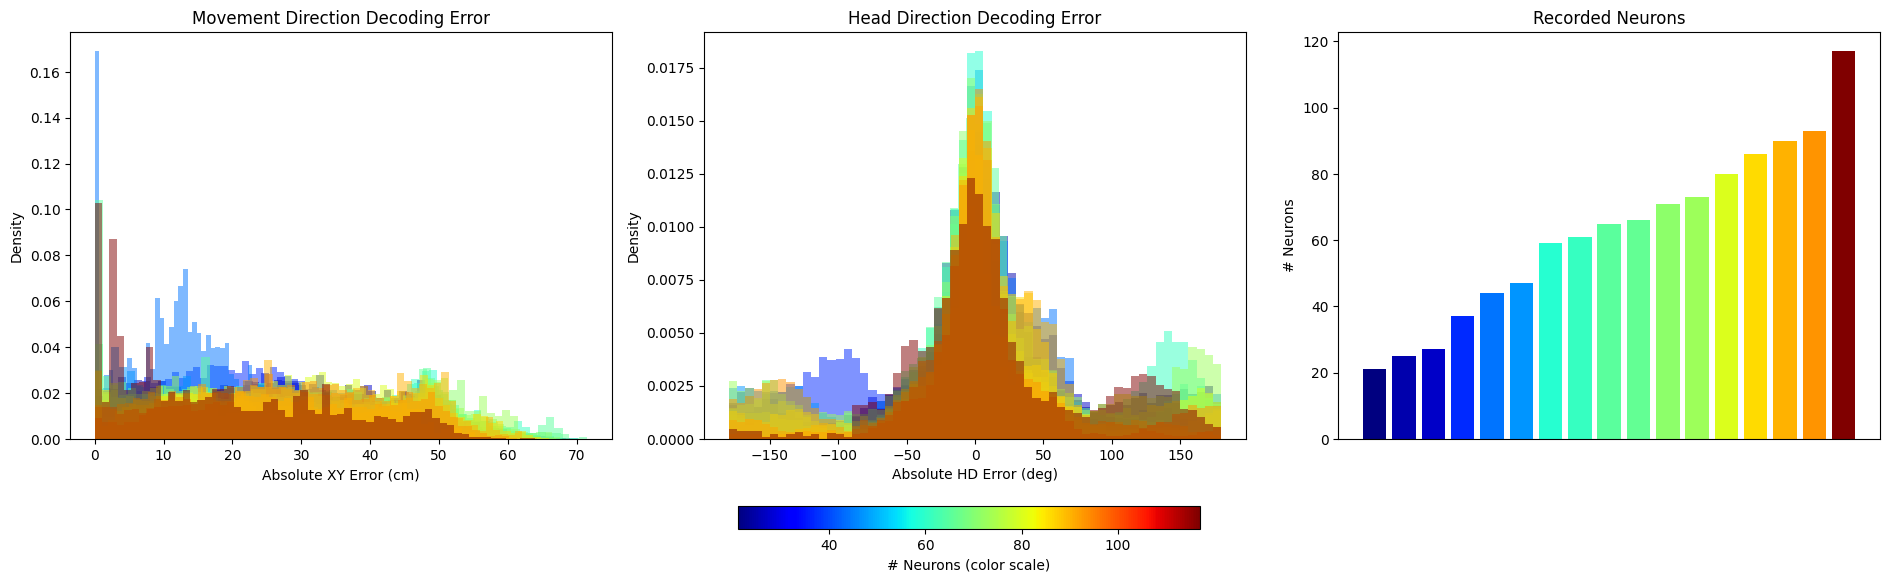

In [13]:
from __future__ import annotations
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import json
import re

# -----------------------------------------------------------------------------
# Notebook-friendly version (no main()).
# Assumes:
#   - save_path: Path containing 'hd_neuron_counts.json' and rat subfolders
#   - current_file_path: Path to project root for saving output figures
#   - dusz_datasets: mapping like dusz_datasets[dataset_id][session] -> (envType, ...)
# -----------------------------------------------------------------------------

# =============== Helpers ===============

def _sanitize(name: str) -> str:
    """Make a safe filename from a rat identifier like 'Dataset_1/A3708-200317b'."""
    return re.sub(r"[^A-Za-z0-9_.-]", "_", name)


def load_precomp_xy_hd(save_path: Path, dusz_datasets) -> list[dict]:
    """Load XY (pos/MD-as-XY) and HD decoding errors, preferring 'used' neuron count.

    Returns list of dicts: {"rat", "neurons", "xy", "hd"} for each included rat.
    """
    with open(save_path / 'hd_neuron_counts.json', 'r') as f:
        rat_neuron_dict = json.load(f)

    pairs = sorted(rat_neuron_dict.items(), key=lambda x: x[1])
    rats, rat_neurons = map(np.array, zip(*pairs))
    rat_neurons = rat_neurons.astype(float)

    precomp = []
    for rat, n_neurons_json in zip(rats, rat_neurons):
        rat_parts = rat.split('/')
        dataset = int(rat_parts[0][-1])
        session = rat_parts[1]

        # Keep only square env; skip specific problematic rat (as in original)
        if session in dusz_datasets.get(dataset, {}) \
           and dusz_datasets[dataset][session][0] != 'Square' \
           and rat != 'Dataset_1/A3708-200317b':
            continue
        if rat == 'Dataset_4/A8603-210602':
            continue

        save_path_rat = save_path / rat

        # ---------- Prefer "used" neuron count if available ----------
        n_neurons_used = float(n_neurons_json)  # fallback to JSON count
        kept_path = save_path_rat / "neurons_kept_hd_filter.npy"
        if kept_path.exists():
            try:
                kept_idx = np.load(kept_path, allow_pickle=True)
                n_neurons_used = float(np.unique(kept_idx).size)
            except Exception:
                pass
        # -------------------------------------------------------------

        # ---------- Adopt the new *_25_all patterns ----------
        # For XY we continue to read from the MD files, but we keep the variable name "xy"
        error_files_xy = sorted(save_path_rat.glob("errors_xy_cv*_10x10_all.npz"))
        error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_25_all.npz"))
        # -----------------------------------------------------

        all_errors_xy, all_errors_hd = [], []

        for f in error_files_xy:
            try:
                data = np.load(f, allow_pickle=True)
                all_errors_xy.append(np.asarray(data["errors"]).ravel())
            except Exception:
                pass

        for f in error_files_hd:
            try:
                data = np.load(f, allow_pickle=True)
                all_errors_hd.append(np.asarray(data["errors_deg"]).ravel())
            except Exception:
                pass

        xy_arr = None
        if all_errors_xy:
            xy_arr = np.concatenate(all_errors_xy)
            xy_arr = xy_arr[~np.isnan(xy_arr)]
            if xy_arr.size == 0:
                xy_arr = None

        hd_arr = None
        if all_errors_hd:
            hd_arr = np.concatenate(all_errors_hd)
            hd_arr = hd_arr[~np.isnan(hd_arr)]
            if hd_arr.size == 0:
                hd_arr = None

        if (xy_arr is not None) and (hd_arr is not None) and np.isfinite(n_neurons_used):
            precomp.append({
                "rat": rat,
                "neurons": float(n_neurons_used),  # use "used" neurons when present
                "xy": xy_arr,
                "hd": hd_arr,
            })

    if not precomp:
        raise RuntimeError("No rats left after filtering; nothing to plot (XY/HD).")

    return precomp


def build_color_map_xy_hd(precomp: list[dict]):
    """Return (norm, cmap, color_by_rat, neurons_array) using neurons to color."""
    cmap = plt.get_cmap('jet')
    neurons = np.array([d["neurons"] for d in precomp], dtype=float)
    norm = Normalize(vmin=np.nanmin(neurons), vmax=np.nanmax(neurons))
    color_by_rat = {d["rat"]: cmap(norm(d["neurons"])) for d in precomp}
    return norm, cmap, color_by_rat, neurons


def plot_all_xy_hd(precomp: list[dict], color_by_rat: dict, norm, cmap, outdir: Path,
                   bins: int = 60, density: bool = True, dpi: int = 300):
    """Combined XY + HD overlays + neuron bars, shared colorbar (XY/HD)."""
    outdir.mkdir(parents=True, exist_ok=True)

    fig, axs = plt.subplots(1, 3, figsize=(19, 6))

    # Overlaid XY
    for d in precomp:
        c = color_by_rat[d["rat"]]
        axs[0].hist(d["xy"], bins=bins, alpha=0.5, density=density, color=c)
    axs[0].set_xlabel("Absolute XY Error (cm)")  # keep your XY label
    axs[0].set_ylabel("Density")
    axs[0].set_title("Movement Direction Decoding Error")  # keep your original title text

    # Overlaid HD
    for d in precomp:
        c = color_by_rat[d["rat"]]
        axs[1].hist(d["hd"], bins=bins, alpha=0.5, density=density, color=c)
    axs[1].set_xlabel("Absolute HD Error (deg)")
    axs[1].set_ylabel("Density")
    axs[1].set_title("Head Direction Decoding Error")

    # Neuron bars, order as in precomp
    neurons = np.array([d["neurons"] for d in precomp], dtype=float)
    bar_colors = [color_by_rat[d["rat"]] for d in precomp]
    x = np.arange(len(precomp))
    axs[2].bar(x, neurons, color=bar_colors)
    axs[2].set_xticks([])
    axs[2].set_ylabel("# Neurons")
    axs[2].set_title("Recorded Neurons")

    # Match y-lims between XY/HD panels
    #axs[0].set_ylim(axs[1].get_ylim())

    # Shared colorbar for neuron count
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    fig.colorbar(sm, ax=axs, orientation='horizontal', fraction=0.05, pad=0.12,
                 label="# Neurons (color scale)")

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.26)

    outpath = outdir / 'dusz_1d_decoding_xy_hd__ALL.png'
    fig.savefig(outpath, dpi=dpi)

    xy_ylim = axs[0].get_ylim()
    hd_ylim = axs[1].get_ylim()
    return fig, axs, xy_ylim, hd_ylim


def plot_each_rat_xy_hd(precomp: list[dict], color_by_rat: dict, xy_ylim, hd_ylim,
                        outdir: Path, bins: int = 60, density: bool = True, dpi: int = 300):
    """Per-rat 1x2 figures with XY & HD; annotate N=... (no per-rat bars)."""
    outdir.mkdir(parents=True, exist_ok=True)

    for d in precomp:
        rat = d["rat"]
        c = color_by_rat[rat]
        n_str = f"N={int(round(d['neurons']))} neurons"

        fig, axs = plt.subplots(1, 2, figsize=(13, 5))

        # XY
        axs[0].hist(d["xy"], bins=bins, alpha=0.8, density=density, color=c)
        axs[0].set_xlabel("Absolute XY Error (cm)")
        axs[0].set_ylabel("Density")
        axs[0].set_title(f"Head Direction Error — {rat}")
        if xy_ylim is not None:
            axs[0].set_ylim(xy_ylim)
        axs[0].text(0.98, 0.98, n_str, transform=axs[0].transAxes,
                    ha='right', va='top', fontsize=10)

        # HD
        axs[1].hist(d["hd"], bins=bins, alpha=0.8, density=density, color=c)
        axs[1].set_xlabel("Absolute HD Error (deg)")
        axs[1].set_ylabel("Density")
        axs[1].set_title(f"Head Direction Error — {rat}")
        if hd_ylim is not None:
            axs[1].set_ylim(hd_ylim)
        axs[1].text(0.98, 0.98, n_str, transform=axs[1].transAxes,
                    ha='right', va='top', fontsize=10)

        plt.tight_layout()
        outpath = outdir / f'dusz_1d_decoding_xy_hd__{_sanitize(rat)}.png'
        fig.savefig(outpath, dpi=dpi)
        plt.close(fig)

# 1) Build the dataset (XY/HD, with "used" neuron count when available)
precomp_xy_hd = load_precomp_xy_hd(save_path, dusz_datasets)

# 2) Build colors keyed by rat (based on neuron count)
norm_xy_hd, cmap_xy_hd, color_by_rat_xy_hd, _ = build_color_map_xy_hd(precomp_xy_hd)

# 3) Output directories
figs_dir = current_file_path / 'figs'
indiv_dir = figs_dir / 'dusz_individual_decode_xy'
figs_dir.mkdir(parents=True, exist_ok=True)
indiv_dir.mkdir(parents=True, exist_ok=True)

# 4) Plot combined, then per rat (same colors; per-rat N annotation)
_, _, xy_ylim, hd_ylim = plot_all_xy_hd(precomp_xy_hd, color_by_rat_xy_hd, norm_xy_hd, cmap_xy_hd, figs_dir)
plot_each_rat_xy_hd(precomp_xy_hd, color_by_rat_xy_hd, xy_ylim, hd_ylim, indiv_dir)


In [20]:
rat_neurons

NameError: name 'rat_neurons' is not defined

### Decoding MD from Dusz HD cells

/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_2/A5507-200920
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3708-200317b
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_2/A6216-210623
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3730-210323b
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3717-201021
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3702-191126
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3703-191215
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3705-200306
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3701-191119
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3712-200903a
/content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/Dataset_1/A3710-200609
/content/drive/MyDrive/ve/var

/tmp/ipython-input-2485963748.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


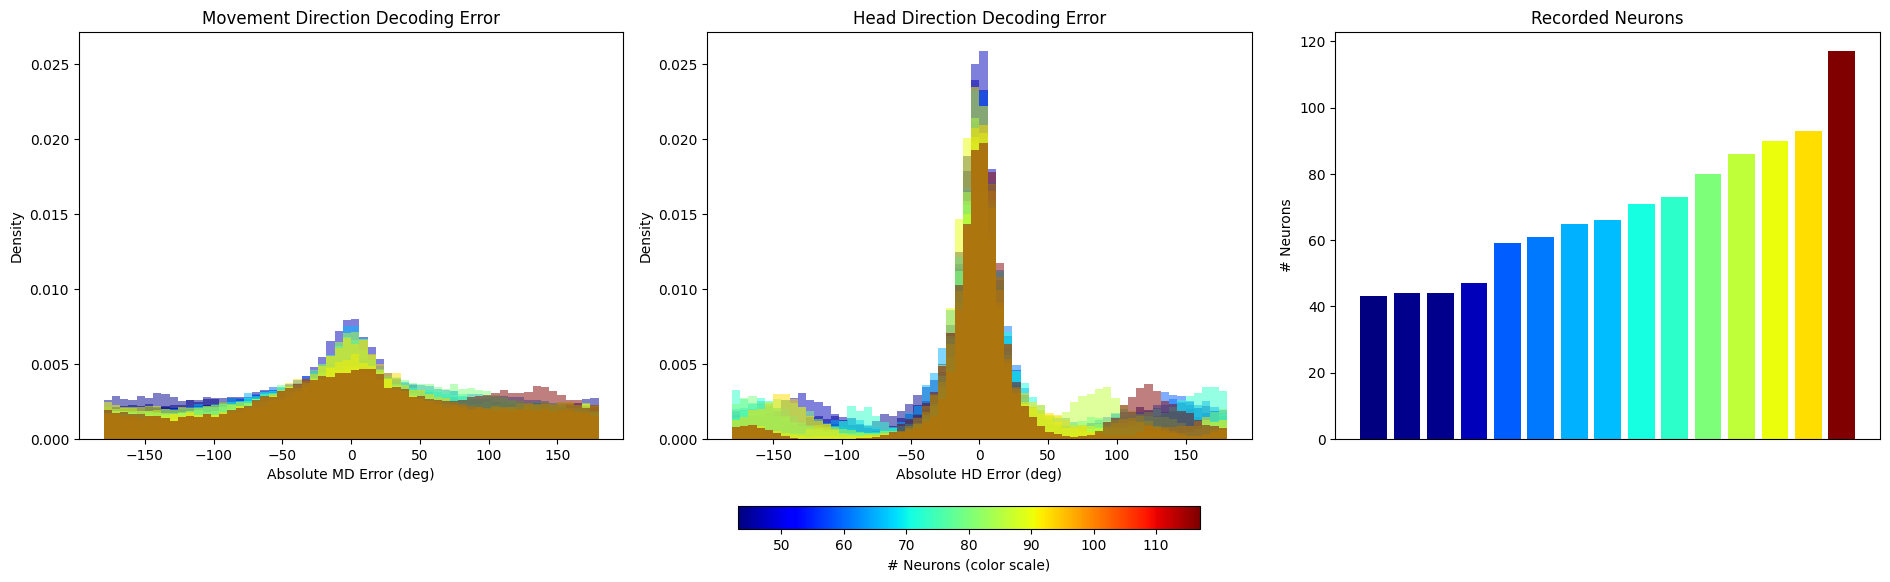

In [13]:
from __future__ import annotations
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import json
import re

EXCLUDE_UNDER_30 = False  # set True to skip plotting rats with < MIN_NEURONS_FOR_PLOTS
MIN_NEURONS_FOR_PLOTS = 30

def _sanitize(name: str) -> str:
    """Make a safe filename from a rat identifier like 'Dataset_1/A3708-200317b'."""
    return re.sub(r"[^A-Za-z0-9_.-]", "_", name)


def load_precomp_md_hd(save_path: Path, dusz_datasets) -> list[dict]:
    """Load MD and HD decoding errors and neuron counts with the **used** neurons if available.

    Returns a list of dicts: {"rat", "neurons", "md", "hd"} for each included rat.
    """
    with open(save_path / 'hd_neuron_counts.json', 'r') as f:
        rat_neuron_dict = json.load(f)

    pairs = sorted(rat_neuron_dict.items(), key=lambda x: x[1])
    rats, rat_neurons = map(np.array, zip(*pairs))
    rat_neurons = rat_neurons.astype(float)

    precomp = []
    for rat, n_neurons_json in zip(rats, rat_neurons):
        rat_parts = rat.split('/')
        dataset = int(rat_parts[0][-1])
        session = rat_parts[1]

        # Keep only square env; skip one problematic rat as in your original code
        if session in dusz_datasets.get(dataset, {}) \
           and dusz_datasets[dataset][session][0] != 'Square' \
           and rat != 'Dataset_1/A3708-200317b':
            continue
        if rat == 'Dataset_4/A8603-210602':
            continue

        #if rat != 'Dataset_2/A1815-190523':
            # just testing
        #    continue

        save_path_rat = save_path / rat

        # ---------- NEW: prefer "used" neuron count if the file exists ----------
        n_neurons_used = float(n_neurons_json)  # fallback
        kept_path = save_path_rat / "neurons_kept_hd_filter.npy"
        if kept_path.exists():
            try:
                kept_idx = np.load(kept_path, allow_pickle=True)
                # robustly count unique indices
                n_neurons_used = float(np.unique(kept_idx).size)
            except Exception:
                # keep fallback if any issue loading/reading file
                pass
        # -----------------------------------------------------------------------
        if n_neurons_used < 40:
          continue

        print(save_path_rat)
        error_files_md = sorted(save_path_rat.glob("errors_md_cv*_360_all.npz"))
        error_files_hd = sorted(save_path_rat.glob("errors_hd_cv*_360_all.npz"))

        md_list, hd_list = [], []
        for f in error_files_md:
            try:
                data = np.load(f, allow_pickle=True)
                md_list.append(np.asarray(data["errors_deg"]).ravel())
            except Exception:
                pass
        for f in error_files_hd:
            try:
                data = np.load(f, allow_pickle=True)
                hd_list.append(np.asarray(data["errors_deg"]).ravel())
            except Exception:
                pass

        md_arr = None
        if md_list:
            md_arr = np.concatenate(md_list)
            md_arr = md_arr[~np.isnan(md_arr)]
            if md_arr.size == 0:
                md_arr = None

        hd_arr = None
        if hd_list:
            hd_arr = np.concatenate(hd_list)
            hd_arr = hd_arr[~np.isnan(hd_arr)]
            if hd_arr.size == 0:
                hd_arr = None

        if ((md_arr is not None) and (hd_arr is not None)) and np.isfinite(n_neurons_used):
            precomp.append({
                "rat": rat,
                "neurons": float(n_neurons_used),  # <-- now "used" neurons
                "md": md_arr,
                "hd": hd_arr,
            })

    if not precomp:
        raise RuntimeError("No rats left after filtering; nothing to plot (MD/HD).")

    return precomp



def build_color_map_md_hd(precomp: list[dict]):
    """Return (norm, cmap, color_by_rat, neurons_array) using neurons to color."""
    cmap = plt.get_cmap('jet')
    neurons = np.array([d["neurons"] for d in precomp], dtype=float)
    norm = Normalize(vmin=np.nanmin(neurons), vmax=np.nanmax(neurons))
    color_by_rat = {d["rat"]: cmap(norm(d["neurons"])) for d in precomp}
    return norm, cmap, color_by_rat, neurons


def plot_all_md_hd(precomp: list[dict], color_by_rat: dict, norm, cmap, outdir: Path,
                   bins: int = 60, density: bool = True, dpi: int = 300):
    """Combined MD + HD overlays + neuron bars, shared colorbar (MD/HD only)."""
    outdir.mkdir(parents=True, exist_ok=True)

    fig, axs = plt.subplots(1, 3, figsize=(19, 6))

    # Overlaid MD
    for d in precomp:
        c = color_by_rat[d["rat"]]
        axs[0].hist(d["md"], bins=bins, alpha=0.5, density=density, color=c)
    axs[0].set_xlabel("Absolute MD Error (deg)")
    axs[0].set_ylabel("Density")
    axs[0].set_title("Movement Direction Decoding Error")

    # Overlaid HD
    for d in precomp:
        c = color_by_rat[d["rat"]]
        axs[1].hist(d["hd"], bins=bins, alpha=0.5, density=density, color=c)
    axs[1].set_xlabel("Absolute HD Error (deg)")
    axs[1].set_ylabel("Density")
    axs[1].set_title("Head Direction Decoding Error")

    # Neuron bars
    neurons = np.array([d["neurons"] for d in precomp], dtype=float)
    bar_colors = [color_by_rat[d["rat"]] for d in precomp]
    x = np.arange(len(precomp))
    axs[2].bar(x, neurons, color=bar_colors)
    axs[2].set_xticks([])
    axs[2].set_ylabel("# Neurons")
    axs[2].set_title("Recorded Neurons")

    # Match y-lims between MD/HD panels
    axs[0].set_ylim(axs[1].get_ylim())

    # Shared colorbar for neuron count
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    fig.colorbar(sm, ax=axs, orientation='horizontal', fraction=0.05, pad=0.12,
                 label="# Neurons (color scale)")

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.26)

    outpath = outdir / 'dusz_1d_decoding_md_hd__ALL.png'
    fig.savefig(outpath, dpi=dpi)

    md_ylim = axs[0].get_ylim()
    hd_ylim = axs[1].get_ylim()
    return fig, axs, md_ylim, hd_ylim


def plot_each_rat_md_hd(precomp: list[dict], color_by_rat: dict, md_ylim, hd_ylim,
                        outdir: Path, bins: int = 60, density: bool = True, dpi: int = 300):
    """Per-rat 1x2 figures with MD & HD; annotate N=... instead of bar plot."""
    outdir.mkdir(parents=True, exist_ok=True)

    for d in precomp:
        rat = d["rat"]
        c = color_by_rat[rat]
        n_str = f"N={int(round(d['neurons']))} neurons"

        fig, axs = plt.subplots(1, 2, figsize=(13, 5))

        # MD
        axs[0].hist(d["md"], bins=bins, alpha=0.8, density=density, color=c)
        axs[0].set_xlabel("Absolute MD Error (deg)")
        axs[0].set_ylabel("Density")
        axs[0].set_title(f"Movement Direction Error — {rat}")
        if md_ylim is not None:
            axs[0].set_ylim(md_ylim)
        axs[0].text(0.98, 0.98, n_str, transform=axs[0].transAxes,
                    ha='right', va='top', fontsize=10)

        # HD
        axs[1].hist(d["hd"], bins=bins, alpha=0.8, density=density, color=c)
        axs[1].set_xlabel("Absolute HD Error (deg)")
        axs[1].set_ylabel("Density")
        axs[1].set_title(f"Head Direction Error — {rat}")
        if hd_ylim is not None:
            axs[1].set_ylim(hd_ylim)
        axs[1].text(0.98, 0.98, n_str, transform=axs[1].transAxes,
                    ha='right', va='top', fontsize=10)

        plt.tight_layout()
        outpath = outdir / f'dusz_1d_decoding_md_hd__{_sanitize(rat)}.png'
        fig.savefig(outpath, dpi=dpi)
        plt.close(fig)

# ===================== Execute MD/HD pipeline =====================
# Build dataset
precomp_md_hd = load_precomp_md_hd(save_path, dusz_datasets)

# Colors keyed by rat (based on neuron count)
norm_md_hd, cmap_md_hd, color_by_rat_md_hd, _ = build_color_map_md_hd(precomp_md_hd)

# Output dirs
md_figs_dir = current_file_path / 'figs'
md_indiv_dir = md_figs_dir / 'dusz_individual_decode_md'
md_figs_dir.mkdir(parents=True, exist_ok=True)
md_indiv_dir.mkdir(parents=True, exist_ok=True)

# Plot combined, then individual (no bars per rat; N label instead)
_, _, md_ylim, hd_ylim = plot_all_md_hd(precomp_md_hd, color_by_rat_md_hd, norm_md_hd, cmap_md_hd, md_figs_dir)
plot_each_rat_md_hd(precomp_md_hd, color_by_rat_md_hd, md_ylim, hd_ylim, md_indiv_dir)


### extra: count the hd neurons and store

In [30]:
# %% [markdown]
# Collect a dictionary of session titles -> HD neuron counts for Dusz dataset

# %%
from pathlib import Path
import numpy as np
from scipy.io import loadmat

# -- robust MATLAB struct extractor (matches your pipeline) --
def _extract_matlab_obj(obj):
    try:
        from scipy.io.matlab._mio5_params import mat_struct
    except Exception:
        mat_struct = ()  # fallback if internal path changes
    if not (isinstance(obj, dict) or isinstance(obj, mat_struct)):
        return obj
    d = obj.__dict__ if hasattr(obj, "__dict__") else obj
    out = {}
    for k, v in d.items():
        if k in ["_fieldnames", "type", "time_unit", "data_unit", "name"]:
            continue
        if hasattr(v, "__dict__") or isinstance(v, dict):
            out[k] = _extract_matlab_obj(v)
        elif isinstance(v, np.ndarray):
            out[k] = np.array([_extract_matlab_obj(x) for x in v])
        else:
            out[k] = v
    return out

def _to_1d_int(arr):
    a = np.asarray(arr).ravel()
    # convert booleans or truthy to ints
    if a.dtype == bool:
        a = a.astype(int)
    return a.astype(int, copy=False)

def count_hd_neurons(celltypes_mat_path: Path) -> int:
    """Return number of HD neurons (hd == 1) from a Dusz CellTypes.mat file."""
    ct_raw = loadmat(celltypes_mat_path, struct_as_record=False, squeeze_me=True)
    # Commonly the struct is under 'CellTypes', but support variants.
    ct = _extract_matlab_obj(ct_raw.get('CellTypes', ct_raw))
    # Try several likely places for the hd vector
    candidates = [
        ct.get('hd'),
        ct_raw.get('hd'),
        (ct.get('labels', {}) if isinstance(ct.get('labels'), dict) else {}).get('hd'),
    ]
    hd_vec = None
    for c in candidates:
        if c is not None and np.size(c) > 0:
            hd_vec = _to_1d_int(c)
            break
    if hd_vec is None:
        raise FileNotFoundError(f"Couldn't find 'hd' labels in {celltypes_mat_path}")
    # Convention: hd == 1 means HD cell
    return int(np.sum(hd_vec == 1))

def gather_hd_counts(
    data_root: Path = Path("./data/dusz"),
    sessions: list[tuple[int, str]] | None = None,
) -> dict[str, int]:
    """
    Build { 'Dataset_{id}/RAT': hd_count }.
    If `sessions` is None, auto-discovers all Dataset_*/*/Data/CellTypes.mat.
    """
    results: dict[str, int] = {}
    if sessions is None:
        for ct_path in sorted(data_root.glob("Dataset_*/*/Data/CellTypes.mat")):
            dataset_str = ct_path.parts[-4]  # "Dataset_{id}"
            rat = ct_path.parts[-3]
            title = f"{dataset_str}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception as e:
                results[title] = -1  # mark failure
    else:
        for ds_id, rat in sessions:
            ct_path = data_root / f"Dataset_{ds_id}" / rat / "Data" / "CellTypes.mat"
            title = f"Dataset_{ds_id}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception:
                results[title] = -1
    return results


hd_counts = gather_hd_counts(Path(data_path), sessions=session_list)

# Print the dictionary (and a neat summary)
print(hd_counts)
print("\nSummary:")
ok = {k: v for k, v in hd_counts.items() if v >= 0}
fail = [k for k, v in hd_counts.items() if v < 0]
print(f"  Sessions found: {len(hd_counts)}")
print(f"  With counts    : {len(ok)} (total HD neurons = {sum(ok.values())})")
if fail:
    print(f"  Failed to read : {len(fail)} -> {fail}")


import json
from pathlib import Path

# --- after computing hd_counts ---
output_path = Path(save_path / "hd_neuron_counts.json")

# Save dictionary to JSON
with open(output_path, "w") as f:
    json.dump(hd_counts, f, indent=2)  # indent makes it nicely formatted

print(f"Saved HD counts to {output_path}")

# --- later on, when you want to load it ---
with open(output_path, "r") as f:
    loaded_hd_counts = json.load(f)

print("Loaded HD counts:", loaded_hd_counts)



{'Dataset_1/A3701-191119': 71, 'Dataset_1/A3702-191126': 61, 'Dataset_1/A3703-191215': 65, 'Dataset_1/A3705-200306': 66, 'Dataset_1/A3706-200313': 86, 'Dataset_1/A3707-200317': 117, 'Dataset_1/A3708-200317b': 44, 'Dataset_1/A3709-200601': 21, 'Dataset_1/A3710-200609': 80, 'Dataset_1/A3711-200810b': 90, 'Dataset_1/A3712-200903a': 73, 'Dataset_1/A3713-200909a': 25, 'Dataset_1/A3716-201015b': 93, 'Dataset_1/A3717-201021': 59, 'Dataset_1/A3723-201115': 37, 'Dataset_1/A3728-210309b': 27, 'Dataset_1/A3730-210323b': 47, 'Dataset_2/A1808-190807': 29, 'Dataset_2/A1813-190408': 30, 'Dataset_2/A1815-190523': 33, 'Dataset_2/A1821-190910': 37, 'Dataset_2/A1824-190827': 39, 'Dataset_2/A5505-200831': 30, 'Dataset_2/A5506-200914a': 24, 'Dataset_2/A5507-200920': 43, 'Dataset_2/A5508-200930': 33, 'Dataset_2/A5801-200924': 26, 'Dataset_2/A6211-210407': 36, 'Dataset_2/A6215-210610': 29, 'Dataset_2/A6216-210623': 44, 'Dataset_2/A9701-210805': 38}

Summary:
  Sessions found: 31
  With counts    : 31 (total 

In [20]:
!ls /content/drive/MyDrive/ve/variance_analysis/data/rodents/dusz/
# /content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/

Dataset_1  Dataset_metadata.xlsx  hd_neuron_counts.json


In [25]:
dusz_datasets

{1: {'A3701-191119': ('Square', 102),
  'A3702-191126': ('Square', 90),
  'A3703-191215': ('Square', 103),
  'A3705-200306': ('Square', 117),
  'A3706-200313': ('Square', 126),
  'A3707-200317': ('Square', 185),
  'A3708-200317b': ('Triangle', 78),
  'A3709-200601': ('Square', 64),
  'A3710-200609': ('Square', 107),
  'A3711-200810b': ('Square', 142),
  'A3712-200903a': ('Square', 126),
  'A3713-200909a': ('Square', 88),
  'A3716-201015b': ('Square', 147),
  'A3717-201021': ('Square', 98),
  'A3723-201115': ('Square', 68),
  'A3728-210309b': ('Square', 42),
  'A3730-210323b': ('Square', 77)},
 2: {'A1808-190807': ('Square', 101),
  'A1813-190408': ('Square', 70),
  'A1815-190523': ('Square', 65),
  'A1821-190910': ('Square', 74),
  'A1824-190827': ('Square', 70),
  'A5505-200831': ('Square', 55),
  'A5506-200914a': ('Square', 49),
  'A5507-200920': ('Square', 96),
  'A5508-200930': ('Square', 52),
  'A5801-200924': ('Square', 46),
  'A6211-210407': ('Square', 61),
  'A6215-210610': ('S

In [26]:
session_list = [(1, r) for r in dusz_datasets[1].keys()]

In [27]:
session_list

[(1, 'A3701-191119'),
 (1, 'A3702-191126'),
 (1, 'A3703-191215'),
 (1, 'A3705-200306'),
 (1, 'A3706-200313'),
 (1, 'A3707-200317'),
 (1, 'A3708-200317b'),
 (1, 'A3709-200601'),
 (1, 'A3710-200609'),
 (1, 'A3711-200810b'),
 (1, 'A3712-200903a'),
 (1, 'A3713-200909a'),
 (1, 'A3716-201015b'),
 (1, 'A3717-201021'),
 (1, 'A3723-201115'),
 (1, 'A3728-210309b'),
 (1, 'A3730-210323b')]

In [28]:
session_list.extend([(2, r) for r in dusz_datasets[2].keys()])

In [29]:
session_list

[(1, 'A3701-191119'),
 (1, 'A3702-191126'),
 (1, 'A3703-191215'),
 (1, 'A3705-200306'),
 (1, 'A3706-200313'),
 (1, 'A3707-200317'),
 (1, 'A3708-200317b'),
 (1, 'A3709-200601'),
 (1, 'A3710-200609'),
 (1, 'A3711-200810b'),
 (1, 'A3712-200903a'),
 (1, 'A3713-200909a'),
 (1, 'A3716-201015b'),
 (1, 'A3717-201021'),
 (1, 'A3723-201115'),
 (1, 'A3728-210309b'),
 (1, 'A3730-210323b'),
 (2, 'A1808-190807'),
 (2, 'A1813-190408'),
 (2, 'A1815-190523'),
 (2, 'A1821-190910'),
 (2, 'A1824-190827'),
 (2, 'A5505-200831'),
 (2, 'A5506-200914a'),
 (2, 'A5507-200920'),
 (2, 'A5508-200930'),
 (2, 'A5801-200924'),
 (2, 'A6211-210407'),
 (2, 'A6215-210610'),
 (2, 'A6216-210623'),
 (2, 'A9701-210805')]